In [1]:
%pip install scikit-learn numpy matplotlib seaborn imbalanced-learn
low_memory=False
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import imblearn
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

Note: you may need to restart the kernel to use updated packages.


## From numbers to categories
- so far we've focused on continuous values like price,temo,scores..but what if we need to predict categories instead?
# Classification problems in real life
- spam detection: is this email spam
- medical diagnosis: does the patient have a disease
- image recognition: what digit is in this image
- customer behaviour: will this customer buy our product?
Linear regression has a major problem with categories..it can predict any number like 2.7-10.5
but categories need specific value
# logistic regression solves this problem by:
- taking our inputs as usual
- running them through a special function
- giving outputs that represent probabilities(0-1)
- converting probabilities to specific categories


# problem setting
# the handwritten digit recongnition :ML recognizing handwritten digits
we will use the digits dataset from scikit learn which contains:
- images of handwritten digits(0-9)
- each image is 8*8 pixels
- is pixel has grayscale value
- each image has a label telling us which digit it represents
# how we will approach this:
- load the images and their label
- examine some sample images
- train a logistic regression model
- make predictions on new images
- evaluate how well our model performs

this is a perfect example of classification- we re sorting images into digit categories,not predicting continuos values!


In [2]:
digits=datasets.load_digits()
dir(digits)
print("Image data shape",digits.data.shape)
print("Label data shape",digits.target.shape)

Image data shape (1797, 64)
Label data shape (1797,)


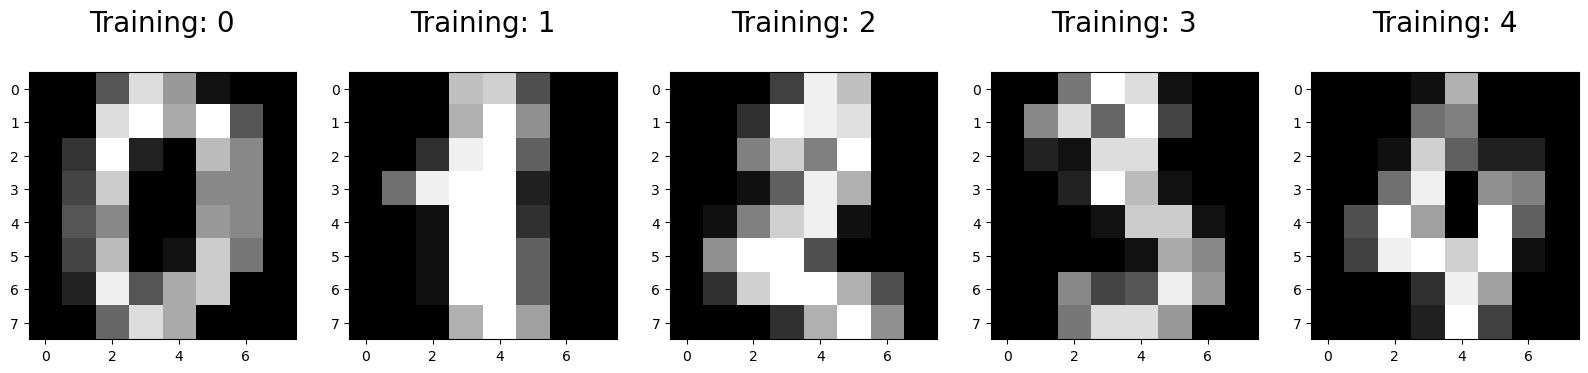

In [3]:
plt.figure(figsize=(20,4))
for index,(image,label) in enumerate(zip(digits.data[0:5],digits.target[0:5])):
    plt.subplot(1,5,index+1)
    plt.imshow(np.reshape(image,(8,8)),cmap=plt.cm.gray)
    plt.title("Training: %i\n" % label,fontsize=20)

# Model
- Lets see how logistic regression transform a linear model into a suitable classification
# First start with linear regression
- take inputs
- muliply by weights
- add a constant
- get a result that can be any number
# apply the sigmoid transformation
for classification we add one crucial step:
- Take the linear regression output
- pass it through a special function call sigmoid transform
- this converts any number into a value between 0 and 1
- the result represent a probability

- The sigmoid function looks like an S-Shaped curve
# sig(t)=1/1+e^-t

# Understanding the sigmoid fun
The sigmoid function is the magic that makes the logistic regression work for classification.
# Key properties
- Always outputs values between 0 and 1
- s shaped curve..(smooth transition between extremes)
- center point at 0.5 probabilty
- steepest at the middle,flatter at extremes
# How to interpret the output
in binary classification(two categories):
- output close to 0: High confidence in category 0
- output close to 1: High confidence in category 1
- output around 0.5: Uncertainity(Could go either way)
# for multiple categories:
for problems with more categories(like our 10 digits):
- we create multiple binary models(one vs rest approach)
- each model predicts probability for one digit
- we choose the category with highest probability

This approach lets us handle both simple yes/no problems and complex multi category problems

# Model estimation
To start off, we will again divide the dataset into test train set.

In [4]:
x_train,x_test,y_train,y_test=train_test_split(digits.data,digits.target,test_size=0.25,random_state=0)

In [5]:
logisticR = LogisticRegression(max_iter=10000)
logisticR.fit(x_train,y_train)

LogisticRegression(max_iter=10000)

In [6]:
print(logisticR.predict(x_test[0].reshape(1,-1)))
print(logisticR.predict(x_test[0:10]))
predictions = logisticR.predict(x_test)
print(predictions)

[2]
[2 8 2 6 6 7 1 9 8 5]
[2 8 2 6 6 7 1 9 8 5 2 8 6 6 6 6 1 0 5 8 8 7 8 4 7 5 4 9 2 9 4 7 6 8 9 4 3
 1 0 1 8 6 7 7 1 0 7 6 2 1 9 6 7 9 0 0 9 1 6 3 0 2 3 4 1 9 2 6 9 1 8 3 5 1
 2 8 2 2 9 7 2 3 6 0 5 3 7 5 1 2 9 9 3 1 4 7 4 8 5 8 5 5 2 5 9 0 7 1 4 7 3
 4 8 9 7 9 8 2 1 5 2 5 8 4 1 7 0 6 1 5 5 9 9 5 9 9 5 7 5 6 2 8 6 9 6 1 5 1
 5 9 9 1 5 3 6 1 8 9 8 7 6 7 6 5 6 0 8 8 9 9 6 1 0 4 1 6 3 8 6 7 4 9 6 3 0
 3 3 3 0 7 7 5 7 8 0 7 1 9 6 4 5 0 1 4 6 4 3 3 0 9 5 9 2 8 4 2 1 6 8 9 2 4
 9 3 7 6 2 3 3 1 6 9 3 6 3 3 2 0 7 6 1 1 9 7 2 7 8 5 5 7 5 3 3 7 2 7 5 5 7
 0 9 1 6 5 9 7 4 3 8 0 3 6 4 6 3 2 6 8 8 8 4 6 7 5 2 4 5 3 2 4 6 9 4 5 4 3
 4 6 2 9 0 1 7 2 0 9 6 0 4 2 0 7 9 8 5 7 8 2 8 4 3 7 2 6 9 9 5 1 0 8 2 8 9
 5 6 2 2 7 2 1 5 1 6 4 5 0 9 4 1 1 7 0 8 9 0 5 4 3 8 8 6 5 3 4 4 4 8 8 7 0
 9 6 3 5 2 3 0 8 8 3 1 3 3 0 0 4 6 0 7 7 6 2 0 4 4 2 3 7 1 9 8 6 8 5 6 2 2
 3 1 7 7 8 0 3 3 2 1 5 5 9 1 3 7 0 0 3 0 4 5 8 9 3 4 3 1 8 9 8 3 6 3 1 6 2
 1 7 5 5 1 9]


# Model Evaluation
we used metrics like r2 and mse for simple regression model...but for classfication we need diff tools
## The four basic outcomes
# true positive(Tp):
- we predicted "yes.Its a digit 7"
- reality: It is digit 7
- example: correctly identifying a cancer patient
# true negetive(TN):
- we predicted: No its not digit 7
- reality its not digit 7
- example: Correctly identifying a healthy patient
# false positive(FP):
- we predicted: Yes its a digit 7
- reality: Its actually 1
- example: false alarm(diagnosing healthy person with disease)
- also called a type error
# False negetive(FN):
- we predicted: NO its not digit 7
- reality: it actually is digit 7
- example : Missing a diagnosis(Failing to detect disease)

This four outcomes are the building blocks for all evaluation metrics


# Accuracy: The most intuitive metric
Accuracy is the simplest and most intuitive evaluation metric for classification models
- accuracy measures the percentage of predictions that are correct:
- Accuracy = (number of correct pred)/(total number of pred)
- Accuracy = TP+TN/(TP+TN+FP+FN) 
# When accuracy works well:
- balanced classes(Similar numbers of each category)
- equal importance of all types of errors
# When accuracy can be misleading
- imbalanced classes(rare diseases,fraud detection)
- dufferent cost for diff types of errors


In [7]:
test_pred = logisticR.predict(x_test)
accuracy = accuracy_score(y_test,test_pred)
print(accuracy)

0.9533333333333334


# Precision: When false positive matter
precision focuses on the quality of positive predictions.It answers the question "when we predict the positive class,how often we are right?
- precision measures the accuracy of positive predictions:
# Precision = tp/tp+fp


In [8]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       0.91      0.93      0.92        43
           2       0.98      0.93      0.95        44
           3       0.91      0.96      0.93        45
           4       0.97      0.97      0.97        38
           5       0.98      0.96      0.97        48
           6       1.00      0.98      0.99        52
           7       0.98      0.96      0.97        48
           8       0.91      0.90      0.91        48
           9       0.90      0.96      0.93        47

    accuracy                           0.95       450
   macro avg       0.95      0.95      0.95       450
weighted avg       0.95      0.95      0.95       450



In [11]:
# Calculating the global precision
print(precision_score(y_test,predictions,average="weighted"))

0.9541907627439542


# Recall and f1 score
recall and specificity are the diff side of the same coin
- while precision focuses on quality of positive , recall and specificity focus on coverage- how well wed catch all the intances of each class
- recall measures how good we are at finding all the positive cases:
# recall = tp/tp+fn
specificity also called true negative rate measures how good we are avoiding false alarms:
# specificity = tn/tn+fp

- high recall needed: Cancer screening, fraud detection etc
- high specificity needed: early screening tests,spam filtering

# F1 score: balancing precision and recall
f1 score = 2*(precision*recall)/(precision+recall)

In [ ]:
print(recall_score(y_test,predictions,average="weighted"))
# the sister of recall is called specificity, or the true neg rate...this metric calculates how well the model identifies negative instances.
# this is usefull when you want a model where there are few false positives

0.9533333333333334


In [13]:
print(specificity_score(y_test,predictions,average='weighted'))

0.9947395539504216


In [14]:
print(f1_score(y_test,predictions,average="weighted"))

0.9535186251861827


# The confusion matrix
somethimes the numbers alone dont tell the whole story...the confusion matrix gives us a visual representation on model performance
- a table showing predicted vs actual model counts
- rows represnt actual classes
- columns represnt predicted classes
- perfect prediciton = numbers only on the diagonal

for multiple classes:
- diagonal elements =  correct predictions
- off diagonal elements = mistakes
- row i,column j = instances of digit i predicted as digit j

In [17]:
cm = metrics.confusion_matrix(y_test,predictions)
print(cm)

[[37  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  2  1]
 [ 0  0 41  3  0  0  0  0  0  0]
 [ 0  0  0 43  0  0  0  0  1  1]
 [ 0  0  0  0 37  0  0  1  0  0]
 [ 0  0  0  0  0 46  0  0  0  2]
 [ 0  1  0  0  0  0 51  0  0  0]
 [ 0  0  0  1  1  0  0 46  0  0]
 [ 0  3  1  0  0  0  0  0 43  1]
 [ 0  0  0  0  0  1  0  0  1 45]]


Text(95.72222222222221, 0.5, 'actual label')

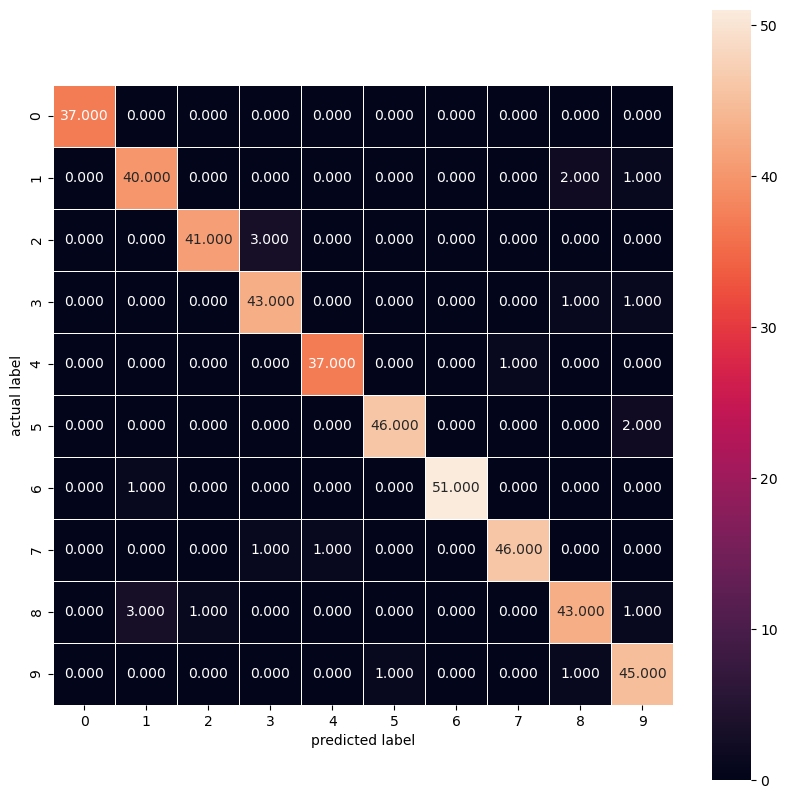

In [27]:
plt.figure(figsize=(10,10))
sns.heatmap(cm,annot=True,linewidths=.5,fmt='.3f',square=True)
plt.xlabel('predicted label')
plt.ylabel("actual label")

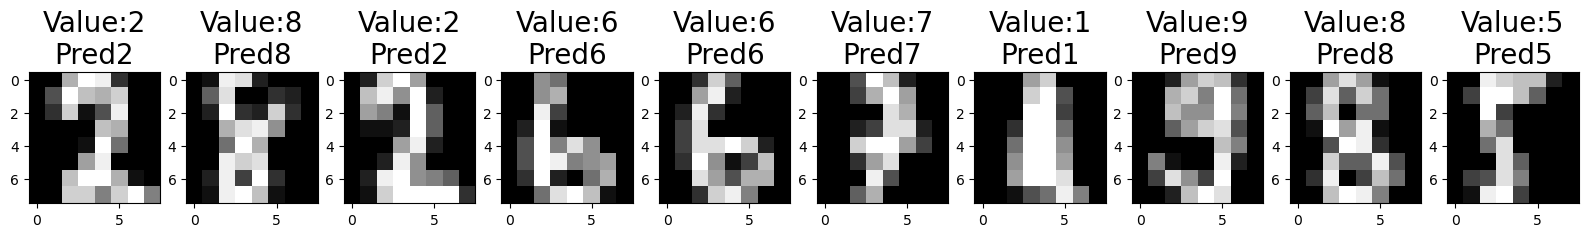

In [29]:
# additional illustration
plt.figure(figsize=(20,4))
predictions=logisticR.predict(x_test[0:10])
for index,(image,label) in enumerate(zip(x_test[0:10],y_test[0:10])):
    plt.subplot(1,10,index+1)
    plt.imshow(np.reshape(image,(8,8)),cmap=plt.cm.gray)
    plt.title(f'Value:{label}\nPred{predictions[index]}',fontsize=20)